In [ ]:
import numpy as np
import pandas as pd
import time

In [3]:
from taco_model import TACOModel
TACO = TACOModel.load("data/taco/taco_model.json")

# TACO viral peptide screening


In [4]:
df_swissprot = pd.read_csv("data/haystack/SwissProt_humanvirus_A0201_NetMHCscored.tsv", sep="\t")
print(f"SwissProt peptides: {len(df_swissprot)} rows, columns: {list(df_swissprot.columns)}")

SwissProt peptides: 1356628 rows, columns: ['hla', 'peptide', 'el_score', 'el_percentile_rank']


In [5]:
df_strong_a0201 = df_swissprot[df_swissprot["el_percentile_rank"] < 0.5].reset_index(drop=True)
peptides_to_eval = df_strong_a0201["peptide"].tolist()
print(f"Strong A*02:01 binders (EL%%rank < 0.5): {len(df_strong_a0201)} peptides")

Strong A*02:01 binders (EL%%rank < 0.5): 19751 peptides


In [6]:
df_tcrvdb_formatted = pd.read_csv("data/haystack/tcrvdb_formatted.tsv", sep="\t")
print(f"TCR data: {len(df_tcrvdb_formatted)} rows, peptides: {sorted(df_tcrvdb_formatted['peptide'].unique())}")

TCR data: 630 rows, peptides: ['GILGFVFTL', 'NLVPMVATV', 'YLQPRTFLL']


In [7]:
# --- Minimum Levenshtein distance: eval peptides vs train/val peptides ---
def _levenshtein(a, b):
    if a == b:
        return 0
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

eval_peptides = sorted(df_tcrvdb_formatted["peptide"].unique())

for split_name, path in [("train", "data/train.tsv"),
                          ("validation", "data/validation.tsv")]:
    split_peps = pd.read_csv(path, sep="	", usecols=["peptide"])["peptide"].unique()
    print(f"{split_name}: {len(split_peps)} unique peptides")
    for ep in eval_peptides:
        dists = [_levenshtein(ep, sp) for sp in split_peps]
        best = min(dists)
        print(f"  {ep}  min Levenshtein = {best}")
    print()

train: 500 unique peptides
  GILGFVFTL  min Levenshtein = 4
  NLVPMVATV  min Levenshtein = 4
  YLQPRTFLL  min Levenshtein = 4

validation: 115 unique peptides
  GILGFVFTL  min Levenshtein = 5
  NLVPMVATV  min Levenshtein = 6
  YLQPRTFLL  min Levenshtein = 4



In [8]:
cdr_cols = ["cdr1a", "cdr2a", "cdr3a", "cdr1b", "cdr2b", "cdr3b"]
df_tcr_input = df_tcrvdb_formatted[cdr_cols].copy()

print(f"Running TACO panel mode: {len(df_tcr_input)} TCRs x {len(peptides_to_eval)} peptides")
t0 = time.time()
df_scores = TACO.predict_proba(df_tcr_input, peptides=peptides_to_eval, parallel=True)
elapsed = time.time() - t0
print(f"  done in {elapsed:.1f}s  ({len(df_tcr_input) * len(peptides_to_eval) / elapsed:,.0f} pred/s)")
print(f"  output shape: {df_scores.shape}")
df_scores.head()

Running TACO panel mode: 630 TCRs x 19751 peptides
  done in 367.6s  (33,852 pred/s)
  output shape: (630, 19751)


,AAADLVVQV,AAAEPLPSL,AAAEVVCEV,AAAGFPLYV,AAAPPPPPV,AAAWYLWEV,AADPPVILL,AADPSIVTL,AAFEFINSL,AAFEHVPTA,AAFGEITSV,AAFGIAPSV,AAFGIHHSV,AAFGNITSV,AAFGVHHSV,AAFHLPPEV,AAFPGTAYV,AAIEQVATV,AAIGAIPGV,AALDYLATV,AALENLVTL,AALENVAKV,AALHLPPEV,AAMDLSHFL,AAMDRIMAL,AAPDWILYV,AAWDGLSEV,AAWDVVYTL,AAWNDIPYL,AAYEDIPAL,AIADLLKSV,AIADLLQSV,AIADLLRSV,AIADNNMRL,AIADNNVRL,AIAEHFNSA,AIAEIYAGL,AIAKSLKEV,AIAPELNAI,AIAPRLLLL,...,YVREHLIKL,YVRERSWSL,YVSDADFSI,YVSDADFSV,YVSDMHTEL,YVSDMHTKL,YVSDSVTLV,YVSDTVTFV,YVSDTVTLV,YVSKLSEQL,YVSLGTLQV,YVSSEIQFL,YVSWGYIYV,YVSWKYIYV,YVSYHTVYI,YVTPISYAV,YVVDVSYGL,YVVEFTTTM,YVVGEIIPL,YVVKFVFEA,YVVSNFEGV,YVVTDIKQV,YVWDGVRGL,YVWGEEVPL,YVWGNHEPV,YVWGNNNPV,YVWKSYVHV,YVWVPSLQV,YVWWKVIYV,YVYALPLKM,YVYDHLTPL,YVYKRGMQL,YVYLDIFSV,YVYNHLTPL,YVYNKLLIL,YVYPLPENM,YVYSFLARL,YVYSFLSTL,YVYSRVKNL,YVYYNLFLL
0,0.065111,0.042285,0.041828,0.023621,0.004980,0.033856,0.021302,0.071643,0.096568,0.043254,0.074285,0.040747,0.016040,0.064421,0.019035,0.007125,0.018201,0.128692,0.011933,0.096559,0.095645,0.012865,0.006359,0.028490,0.047696,0.063258,0.027719,0.165828,0.039614,0.064801,0.036059,0.085404,0.051417,0.017461,0.017585,0.052320,0.038580,0.002069,0.029796,0.005769,...,0.003360,0.037613,0.086709,0.085091,0.026940,0.008709,0.039988,0.056846,0.045345,0.010671,0.025997,0.025080,0.033474,0.021317,0.023868,0.031168,0.070964,0.175853,0.037862,0.010112,0.029775,0.023229,0.015050,0.031082,0.014139,0.027160,0.003083,0.047366,0.029399,0.005298,0.026009,0.003690,0.081597,0.014815,0.010569,0.015433,0.007057,0.056341,0.006209,0.020286
1,0.021943,0.037801,0.012691,0.029429,0.016086,0.006987,0.015138,0.047057,0.081436,0.053527,0.064118,0.045081,0.019574,0.057516,0.020256,0.004218,0.040414,0.085764,0.015144,0.038188,0.044430,0.013100,0.002347,0.015678,0.040963,0.035424,0.008176,0.066292,0.024678,0.043552,0.016055,0.027442,0.018858,0.011228,0.009462,0.034926,0.034480,0.001811,0.022905,0.007070,...,0.012471,0.085948,0.040758,0.039624,0.009382,0.011345,0.017692,0.049174,0.026924,0.008635,0.022290,0.022571,0.025509,0.018171,0.017778,0.043111,0.037597,0.201322,0.035107,0.009101,0.021360,0.028567,0.017881,0.027252,0.014088,0.026891,0.004823,0.034519,0.020960,0.006535,0.019651,0.011778,0.030376,0.014200,0.007166,0.009132,0.008596,0.043888,0.008095,0.010067
2,0.034466,0.040860,0.018665,0.044525,0.016650,0.012576,0.020740,0.078485,0.070348,0.040758,0.072812,0.067506,0.028748,0.100644,0.036962,0.004959,0.055123,0.112018,0.018422,0.049356,0.056892,0.013071,0.003847,0.019327,0.073491,0.040240,0.006106,0.093230,0.025044,0.021168,0.023694,0.045308,0.039961,0.020284,0.018341,0.044788,0.027715,0.003304,0.033823,0.018979,...,0.003865,0.057363,0.029127,0.028691,0.007146,0.007898,0.019723,0.035718,0.027713,0.009424,0.026905,0.017586,0.025874,0.021593,0.024860,0.065797,0.030924,0.134057,0.020835,0.006644,0.019214,0.031082,0.006879,0.008993,0.006722,0.018312,0.004110,0.048632,0.020016,0.005160,0.007858,0.008244,0.022278,0.010072,0.006565,0.007065,0.011344,0.049636,0.012198,0.007406
3,0.059081,0.051885,0.039413,0.042334,0.012301,0.029061,0.018436,0.066525,0.071946,0.049334,0.069401,0.058684,0.025650,0.078892,0.031309,0.008666,0.034395,0.166294,0.024122,0.091673,0.099935,0.020384,0.009624,0.029034,0.066297,0.040300,0.011207,0.109397,0.027964,0.040904,0.039584,0.075455,0.060471,0.023241,0.021282,0.062821,0.051787,0.004528,0.042392,0.014661,...,0.003588,0.029145,0.037801,0.037148,0.011868,0.008510,0.020865,0.033075,0.026174,0.010990,0.031715,0.018218,0.027654,0.021139,0.028196,0.039532,0.035290,0.119793,0.024173,0.007372,0.021332,0.020057,0.008914,0.013550,0.008718,0.018830,0.003935,0.037076,0.021911,0.009252,0.014056,0.006581,0.044280,0.014601,0.009716,0.011002,0.010514,0.050226,0.009561,0.014380
4,0.032778,0.073524,0.036081,0.134931,0.052207,0.037701,0.060302,0.046824,0.058031,0.051134,0.078225,0.078305,0.044227,0.052836,0.037852,0.016081,0.062149,0.091523,0.221096,0.063825,0.053703,0.006942,0.014336,0.055972,0.050861,0.097146,0.012556,0.054468,0.056591,0.075254,0.025579,0.045245,0

In [9]:
keep_cols = ["peptide", "cdr3a", "cdr3b", "TRBV_vdjdb"]
df_result = df_tcrvdb_formatted[keep_cols].reset_index(drop=True).copy()

score_matrix = df_scores.to_numpy()
n_pep = score_matrix.shape[1]
col_lookup = {p: i for i, p in enumerate(df_scores.columns)}
gt_idx = np.array([col_lookup[p] for p in df_result["peptide"]])
gt_score = score_matrix[np.arange(len(score_matrix)), gt_idx]

# Fraction of scanned peptides scoring strictly higher than the true peptide.
# Lower is better: 0.01 = true peptide is in the top 1% of the panel.
# Random baseline = 0.50.
df_result["taco_norm_rank"] = (score_matrix > gt_score[:, None]).sum(axis=1) / n_pep

print(f"Percentile per peptide (lower is better, random baseline = 0.50):")
print(df_result.groupby("peptide")["taco_norm_rank"].describe().round(4))
print(f"\nOverall median: {df_result['taco_norm_rank'].median():.4f}")
df_result.head()

Percentile per peptide (lower is better, random baseline = 0.50):
           count    mean     std     min     25%     50%     75%     max
peptide                                                                 
GILGFVFTL  381.0  0.2638  0.1580  0.0140  0.1532  0.2442  0.3471  0.9436
NLVPMVATV   91.0  0.3094  0.2365  0.0027  0.1206  0.2540  0.4443  0.8682
YLQPRTFLL  158.0  0.3438  0.1928  0.0475  0.1716  0.3110  0.4869  0.8635

Overall median: 0.2597


,peptide,cdr3a,cdr3b,TRBV_vdjdb,taco_norm_rank
0,GILGFVFTL,CAGPGSNTGKLIF,CASSIRSSQPQHF,TRBV19*01,0.242216
1,GILGFVFTL,CAFMKGAGGTSYGKLTF,CASSTGAYGYTF,TRBV19,0.376183
2,GILGFVFTL,CAENMGGGSQGNLIF,CASSIRAGETQYF,TRBV19*01,0.187889
3,GILGFVFTL,CAGAGGGSQGNLIF,CASSIRSTGELFF,TRBV19,0.339628
4,GILGFVFTL,CAGPDGSSNTGKLIF,CASSLIFPGRAFF,TRBV27,0.267176


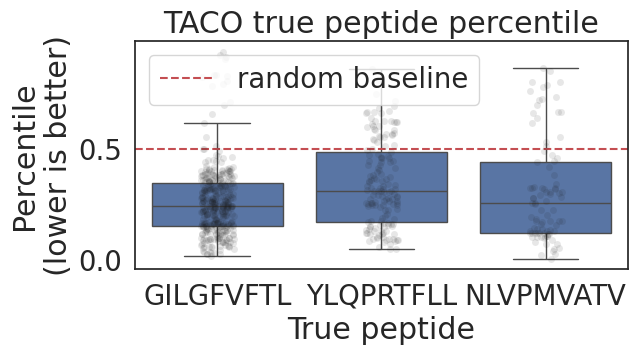

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df_result, x="peptide", y="taco_norm_rank", showfliers=False, ax=ax)
sns.stripplot(data=df_result, x="peptide", y="taco_norm_rank", color="k", alpha=0.1, ax=ax)
ax.axhline(y=0.5, color="r", linestyle="--", label="random baseline")
ax.set_ylabel("Percentile\n(lower is better)")
ax.set_xlabel("True peptide")
ax.set_title("TACO true peptide percentile")
ax.legend()
plt.tight_layout()
plt.show()

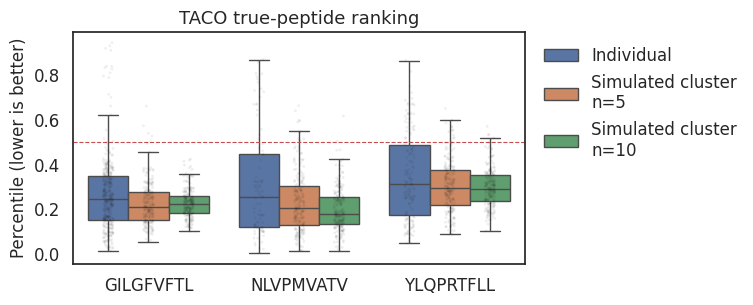

  Individual: median = 0.2597
  Simulated cluster n=5: median = 0.2430
  Simulated cluster n=10: median = 0.2365


In [11]:
# --- Figure 2: simulated TCR clusters ---
rng = np.random.default_rng(42)
cluster_sizes = [5, 10]
n_boot = 200

records_rand = []
for pep in sorted(df_result["peptide"].unique()):
    idxs = np.where(df_result["peptide"] == pep)[0]
    pep_col = col_lookup[pep]

    for i in idxs:
        records_rand.append({
            "peptide": pep, "group": "Individual",
            "percentile": df_result.loc[i, "taco_norm_rank"],
        })

    for cs in cluster_sizes:
        k = min(cs, len(idxs))
        for _ in range(n_boot):
            sample = rng.choice(idxs, size=k, replace=False)
            avg_scores = score_matrix[sample].mean(axis=0)
            gt = avg_scores[pep_col]
            pctile = (avg_scores > gt).sum() / n_pep
            records_rand.append({
                "peptide": pep,
                "group": f"Simulated cluster\nn={cs}",
                "percentile": pctile,
            })

df_rand_clusters = pd.DataFrame(records_rand)
group_order = ["Individual"] + [f"Simulated cluster\nn={cs}" for cs in cluster_sizes]

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(data=df_rand_clusters, x="peptide", y="percentile",
            hue="group", hue_order=group_order, showfliers=False, ax=ax)
sns.stripplot(data=df_rand_clusters, x="peptide", y="percentile",
              hue="group", hue_order=group_order, dodge=True,
              color="k", alpha=0.07, size=2, ax=ax)
ax.axhline(y=0.5, color="r", linestyle="--", linewidth=0.8)
ax.set_ylabel("Percentile (lower is better)", fontsize=12)
ax.set_xlabel("")
ax.tick_params(labelsize=12)
ax.set_title("TACO true-peptide ranking", fontsize=13)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:3], labels[:3], fontsize=12,
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

for g in group_order:
    sub = df_rand_clusters[df_rand_clusters["group"] == g]
    print(f"  {g.replace(chr(10), ' ')}: median = {sub['percentile'].median():.4f}")

In [ ]:
# --- Inference time benchmark: 100 repeats ---
n_repeats = 100
times = []
for i in range(n_repeats):
    t0 = time.time()
    _ = TACO.predict_proba(df_tcr_input, peptides=peptides_to_eval, parallel=True)
    times.append(time.time() - t0)
    if (i + 1) % 10 == 0:
        print(f"  {i+1}/{n_repeats} done")

times = np.array(times)
ci_lo, ci_hi = np.percentile(times, [2.5, 97.5])

print(f"{len(df_tcr_input)} TCRs x {len(peptides_to_eval)} peptides, {n_repeats} repeats")
print(f"  mean   = {times.mean():.2f}s")
print(f"  median = {np.median(times):.2f}s")
print(f"  std    = {times.std():.2f}s")
print(f"  95% CI = [{ci_lo:.2f}, {ci_hi:.2f}]s")
print(f"  throughput = {len(df_tcr_input) * len(peptides_to_eval) / np.median(times):,.0f} pred/s (median)")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))

axes[0].hist(times, bins=20, edgecolor="k", linewidth=0.5)
axes[0].axvline(np.median(times), color="r", linestyle="--", label=f"median {np.median(times):.1f}s")
axes[0].axvline(times.mean(), color="orange", linestyle="--", label=f"mean {times.mean():.1f}s")
axes[0].set_xlabel("Inference time (s)", fontsize=12)
axes[0].set_ylabel("Count", fontsize=12)
axes[0].legend(fontsize=12)
axes[0].tick_params(labelsize=12)

axes[1].plot(range(1, n_repeats + 1), times, ".-", markersize=3, linewidth=0.8)
axes[1].axhline(np.median(times), color="r", linestyle="--", linewidth=0.8)
axes[1].fill_between(range(1, n_repeats + 1), ci_lo, ci_hi, alpha=0.15, color="r")
axes[1].set_xlabel("Repeat", fontsize=12)
axes[1].set_ylabel("Inference time (s)", fontsize=12)
axes[1].tick_params(labelsize=12)

plt.suptitle("TACO panel inference time", fontsize=13)
plt.tight_layout()
plt.show()

  10/100 done
